<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Nearest Neighbors (K-NN) Classification
This notebook demonstrates a complete implementation of the K-NN algorithm using `scikit-learn`, including data scaling, classification evaluation, and a visual representation of decision boundaries.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score

# Set plotting style
sns.set_theme(style="whitegrid")

## 1. Load and Prepare the Dataset
We will use the Iris dataset, selecting two features (Sepal Length and Sepal Width) so that we can easily visualize the decision boundaries in a 2D plot.

In [2]:
# Load dataset
iris = datasets.load_iris()
X = iris.data[:, :2]  # We take the first two features for visual representation
y = iris.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Feature Scaling (Crucial for distance-based algorithms like K-NN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 2. Train and Evaluate the K-NN Model
We will instantiate the model with $k=5$ neighbors and fit it to our scaled training data.

In [3]:
# Initialize K-NN Classifier with k=5
k = 5
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train_scaled, y_train)

# Predict on test set
y_pred = knn.predict(X_test_scaled)

# Print metrics
accuracy = accuracy_score(y_test, y_pred)
print(f"=== Model Evaluation (k={k}) ===\n")
print(f"Accuracy Score: {accuracy:.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

=== Model Evaluation (k=5) ===

Accuracy Score: 68.89%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.52      0.73      0.61        15
   virginica       0.56      0.33      0.42        15

    accuracy                           0.69        45
   macro avg       0.69      0.69      0.68        45
weighted avg       0.69      0.69      0.68        45



## 3. Visualize Decision Boundaries
Now, let's visualize how the classifier divides the feature space into territories for each class.

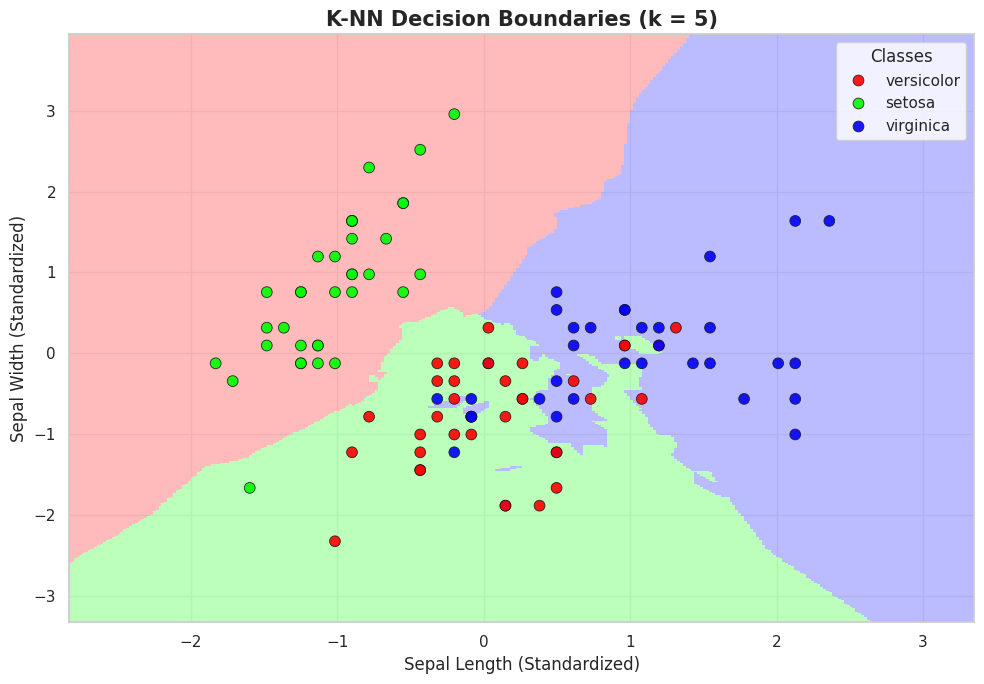

In [4]:
# Create a mesh grid to plot decision boundary
h = 0.02  # Step size in the mesh
x_min, x_max = X_train_scaled[:, 0].min() - 1, X_train_scaled[:, 0].max() + 1
y_min, y_max = X_train_scaled[:, 1].min() - 1, X_train_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Predict classifications for each point in mesh grid
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Create color maps
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ['#FF0000', '#00FF00', '#0000FF']

# Plot
plt.figure(figsize=(10, 7))
plt.pcolormesh(xx, yy, Z, cmap=cmap_light, alpha=0.8)

# Plot training points
sns.scatterplot(
    x=X_train_scaled[:, 0],
    y=X_train_scaled[:, 1],
    hue=iris.target_names[y_train],
    palette=cmap_bold,
    edgecolor='k',
    s=60,
    alpha=0.9
)

plt.title(f"K-NN Decision Boundaries (k = {k})", fontsize=15, fontweight='bold')
plt.xlabel("Sepal Length (Standardized)", fontsize=12)
plt.ylabel("Sepal Width (Standardized)", fontsize=12)
plt.legend(title="Classes", loc="upper right")
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.tight_layout()
plt.show()